# Baku Apartment Listings — ETL Pipeline & Hedonic Price Model
**Daily Data Analytics Project · Day 07**

## Business question
*A Baku property portal receives a messy listings feed. How much of it is usable, and once it is clean, what actually drives the price per m²?*
1. **Data engineering:** turn a raw export (mixed currencies, unit suffixes, 40 district spellings, mixed date formats, reposts, typos) into a validated table in CSV + SQLite.
2. **Analytics:** estimate the premium for district, new building, renovation, title deed (*çıxarış*), metro access and floor with a log-linear **hedonic regression**, then flag mispriced listings for moderators.

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`. The cleaning logic lives in `etl.py`; this notebook shows each step's effect.

In [1]:
import sqlite3, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
import etl
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
raw = etl.load_raw()
print(raw.shape)
raw.sample(8, random_state=0)

(6360, 11)


,listing_id,district,rooms,area,floor,building,renovated,title_deed,metro_nearby,listed_date,price
2087,L105023,nizami r.,3,109.2,4/5,old,1,Bəli,Bəli,21.05.2026,200 700 AZN
4738,L101805,bineqedi,3,91.9 m²,8/12,Köhnə tikili,var,var,Bəli,2026-05-10,167100
2103,L100799,BİNƏQƏDİ,2,68.4 m²,4/4,kohne tikili,var,yes,no,2026-09-24,124700
1270,L100123,nerimanov,2,62.6m2,4/4,Köhnə tikili,0,var,Bəli,21.07.2026,"$124,353"
2378,L102603,Binəqədi,5,155.8,5/5,Köhnə tikili,var,var,Xeyr,2026-07-15,209.9k AZN
3561,L103248,Surakhani,3,"88,9 kv.m",7/9,old,yoxdur,Xeyr,no,2026-04-14,99 400 AZN
2175,L105936,Yasamal,4,117.9 m²,9/17,NaN,yoxdur,yoxdur,yes,2026-02-15,"$171,765"
4688,L103049,Yasamal rayonu,2,63 kv.m,4/5,Köhnə tikili,Bəli,var,yes,2026-03-31,169600 manat


## 1. Raw data audit
What is wrong with the feed before we touch it?

In [2]:
audit = {
 "Rows": len(raw),
 "Exact duplicate rows": int(raw.duplicated().sum()),
 "Distinct district spellings": raw.district.str.strip().nunique(),
 "Prices quoted in USD ($)": int(raw.price.str.startswith("$", na=False).sum()),
 "Prices with 'k' shorthand": int(raw.price.str.contains(r"\dk", na=False).sum()),
 "Prices with text suffix (AZN/manat)": int(raw.price.str.contains("azn|manat", case=False, na=False).sum()),
 "Areas with unit suffix": int(raw.area.str.contains(r"[a-z²]", case=False, na=False).sum()),
 "Areas with decimal comma": int(raw.area.str.contains(r"\d,\d", na=False).sum()),
 "Dates in dd.mm.yyyy format": int(raw.listed_date.str.contains(r"\.", na=False).sum()),
 "Cells with leading/trailing spaces": int(raw.apply(lambda c: c.str.match(r"^\s|.*\s$", na=False)).sum().sum()),
}
display(pd.Series(audit).to_frame("count"))
raw.isna().sum().to_frame("missing").T

,count
Rows,6360
Exact duplicate rows,51
Distinct district spellings,40
Prices quoted in USD ($),1116
Prices with 'k' shorthand,658
Prices with text suffix (AZN/manat),2650
Areas with unit suffix,4461
Areas with decimal comma,882
Dates in dd.mm.yyyy format,2478
Cells with leading/trailing spaces,624


,listing_id,district,rooms,area,floor,building,renovated,title_deed,metro_nearby,listed_date,price
missing,0,69,81,91,0,258,268,282,242,0,61


In [3]:
# 40 spellings collapse to 11 districts
raw.assign(canonical=raw.district.map(etl.norm_district)).groupby("canonical", dropna=False).district \
   .agg(lambda s: sorted(s.dropna().str.strip().unique())).to_frame("raw spellings")

,raw spellings
canonical,
Binagadi,"[Binagadi, Binəqədi, BİNƏQƏDİ, bineqedi]"
Garadagh,"[Garadagh, Qaradağ, qaradag]"
Khatai,"[Khatai, XƏTAİ, Xətai, xetai r.]"
Khazar,"[Khazar, Xəzər, xezer r.]"
Narimanov,"[Narimanov, NƏRİMANOV, Nərimanov, nerimanov]"
Nasimi,"[Nasimi, NƏSİMİ, Nəsimi, Nəsimi rayonu, nesimi..."
Nizami,"[Nizami, NİZAMİ, nizami r.]"
Sabail,"[Sabail, SƏBAİL, Səbail, sebail r.]"
Sabunchu,"[Sabunchu, Sabunçu, sabuncu r.]"


## 2. Extract → Transform
### 2.1 Standardize types and units

In [4]:
std = etl.standardize(raw)
cmp = pd.concat([raw[["district","area","floor","building","price"]].add_prefix("raw_"),
                 std[["district","area","floor","total_floors","new_building","price_azn"]]], axis=1)
cmp.sample(8, random_state=4)

,raw_district,raw_area,raw_floor,raw_building,raw_price,district,area,floor,total_floors,new_building,price_azn
420,BİNƏQƏDİ,29.3m2,4/5,kohne tikili,"$21,824",Binagadi,29.3,4,5,False,37100.0
671,Garadagh,124.3,1/16,Yeni tikili,158 200 AZN,Garadagh,124.3,1,16,True,158200.0
2109,Khatai,113.8 m²,17/20,new,245700 manat,Khatai,113.8,17,20,True,245700.0
5513,nerimanov,139.6 m²,20/24,Yeni tikili,"$320,529",Narimanov,139.6,20,24,True,544900.0
5056,Nəsimi rayonu,"72,6 kv.m",5/5,kohne tikili,200800,Nasimi,72.6,5,5,False,200800.0
2360,YASAMAL,72m2,3/21,Yeni tikili,266 400 AZN,Yasamal,72.0,3,21,True,266400.0
1488,Sabunçu,69.4,1/17,YENİ TİKİLİ,"$50,353",Sabunchu,69.4,1,17,True,85600.0
4957,Nasimi,96.3 m²,11/16,Yeni tikili,365100,Nasimi,96.3,11,16,True,365100.0


In [5]:
print("Unparsed values introduced by parsing (non-null raw -> null clean):")
for r, c in [("district","district"),("area","area"),("price","price_azn"),("building","new_building"),("listed_date","listed_date")]:
    print(f"  {c:14s}", int((raw[r].notna() & std[c].isna()).sum()))

Unparsed values introduced by parsing (non-null raw -> null clean):
  district       0
  area           0
  price_azn      0
  new_building   0
  listed_date    0


### 2.2 De-duplicate
Exact duplicate rows are dropped first; then **reposts** — the same flat (district, rooms, area, floor, price) re-listed under a new id — keep only the earliest listing.

In [6]:
dd, dup_stats = etl.deduplicate(std)
dup_stats, len(dd)

({'exact_duplicates': 60, 'reposts': 289}, 6011)

### 2.3 Validation rules
Rows that break any plausibility rule are quarantined (not silently fixed).

In [7]:
flags = etl.flag_invalid(dd)
rule_tbl = flags.sum().to_frame("rows failing")
rule_tbl["example"] = [dd.loc[flags[c], ["district","rooms","area","floor","total_floors","price_azn"]].head(1).to_dict("records")[0]
                       if flags[c].any() else None for c in flags]
display(rule_tbl)
quarantine = dd[flags.any(axis=1)]
clean = etl.transform(dd[~flags.any(axis=1)]).reset_index(drop=True)
print(f"Quarantined: {len(quarantine):,} | Clean: {len(clean):,}")

,rows failing,example
missing_key_field,293,"{'district': nan, 'rooms': 2, 'area': 86.3, 'f..."
area_out_of_range,15,"{'district': 'Yasamal', 'rooms': 3, 'area': 1...."
price_out_of_range,17,"{'district': 'Sabail', 'rooms': 2, 'area': 72...."
price_per_m2_implausible,50,"{'district': 'Nizami', 'rooms': 2, 'area': 65...."
zero_rooms,8,"{'district': 'Narimanov', 'rooms': 0, 'area': ..."
floor_above_total,10,"{'district': 'Khatai', 'rooms': 2, 'area': 63...."


Quarantined: 360 | Clean: 5,651


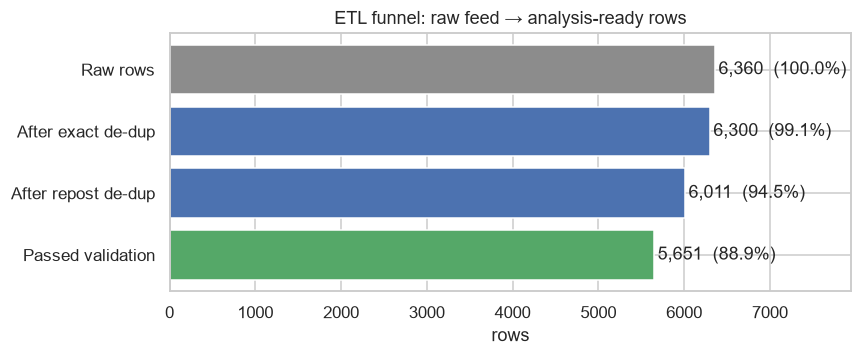

In [8]:
funnel = pd.Series({"Raw rows": len(raw), "After exact de-dup": len(raw) - dup_stats["exact_duplicates"],
                    "After repost de-dup": len(dd), "Passed validation": len(clean)})
fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(funnel.index[::-1], funnel.values[::-1], color=["#55A868", "#4C72B0", "#4C72B0", "#8C8C8C"])
for b, v in zip(bars, funnel.values[::-1]):
    ax.text(v + 40, b.get_y() + b.get_height()/2, f"{v:,}  ({v/len(raw):.1%})", va="center")
ax.set_xlim(0, len(raw) * 1.25); ax.set_title("ETL funnel: raw feed → analysis-ready rows"); ax.set_xlabel("rows")
plt.tight_layout(); plt.savefig("images/etl_funnel.png", bbox_inches="tight"); plt.show()

### 2.4 Post-load assertions
The pipeline fails loudly if any of these break.

In [9]:
checks = {
 "listing_id unique": clean.listing_id.is_unique,
 "no nulls in key fields": clean[["district","rooms","area","price_azn","listed_date"]].notna().all().all(),
 "11 canonical districts": clean.district.nunique() == 11,
 "area within rule": clean.area.between(*etl.RULES["area"]).all(),
 "price/m² within rule": clean.price_per_m2.between(*etl.RULES["price_per_m2"]).all(),
 "floor <= total floors": (clean.floor <= clean.total_floors).all(),
 "dates in 2026": clean.listed_date.dt.year.eq(2026).all(),
}
assert all(checks.values()), checks
pd.Series(checks).to_frame("passed")

,passed
listing_id unique,True
no nulls in key fields,True
11 canonical districts,True
area within rule,True
price/m² within rule,True
floor <= total floors,True
dates in 2026,True


## 3. Load → SQLite
The clean table is written to `data/listings.db` so analysts can query it with SQL.

In [10]:
clean.to_csv("data/clean_listings.csv", index=False)
with sqlite3.connect("data/listings.db") as con:
    clean.assign(listed_date=clean.listed_date.dt.strftime("%Y-%m-%d")).to_sql("listings", con, if_exists="replace", index=False)
    q = '''
    SELECT district,
           COUNT(*)                         AS listings,
           ROUND(AVG(price_per_m2))         AS avg_price_m2,
           ROUND(AVG(price_azn) / 1000, 1)  AS avg_price_k_azn,
           ROUND(100.0 * AVG(new_building), 1) AS new_build_pct,
           RANK() OVER (ORDER BY AVG(price_per_m2) DESC) AS price_rank
    FROM listings GROUP BY district ORDER BY price_rank'''
    sql_tbl = pd.read_sql(q, con)
sql_tbl

,district,listings,avg_price_m2,avg_price_k_azn,new_build_pct,price_rank
0,Sabail,337,4199.0,367.4,45.5,1
1,Nasimi,776,3503.0,300.6,43.2,2
2,Narimanov,598,3110.0,266.1,64.1,3
3,Yasamal,755,3052.0,257.5,61.4,4
4,Khatai,683,2641.0,220.7,63.0,5
5,Nizami,507,2243.0,190.0,59.2,6
6,Binagadi,667,1710.0,140.8,62.1,7
7,Khazar,329,1437.0,120.0,61.1,8
8,Sabunchu,382,1372.0,116.7,59.2,9
9,Surakhani,402,1325.0,112.4,60.5,10


## 4. Business KPIs

In [11]:
kpi = {
 "Raw rows → clean rows": f"{len(raw):,} → {len(clean):,} ({len(clean)/len(raw):.1%} usable)",
 "Duplicates removed (exact + reposts)": f"{dup_stats['exact_duplicates']} + {dup_stats['reposts']}",
 "Rows quarantined by validation": f"{len(quarantine):,}",
 "Prices converted from USD": f"{clean.price_was_usd.mean():.1%}",
 "Median price (AZN)": f"{clean.price_azn.median():,.0f}",
 "Median price per m² (AZN)": f"{clean.price_per_m2.median():,.0f}",
 "Median area (m²)": f"{clean.area.median():.1f}",
 "Most / least expensive district (median AZN/m²)": "{} {:,.0f} / {} {:,.0f}".format(
     *[x for d in [clean.groupby('district').price_per_m2.median().agg(['idxmax','max']),
                   clean.groupby('district').price_per_m2.median().agg(['idxmin','min'])] for x in d]),
}
pd.Series(kpi).to_frame("value")

,value
Raw rows → clean rows,"6,360 → 5,651 (88.9% usable)"
Duplicates removed (exact + reposts),60 + 289
Rows quarantined by validation,360
Prices converted from USD,17.7%
Median price (AZN),"193,000"
Median price per m² (AZN),"2,517"
Median area (m²),83.9
Most / least expensive district (median AZN/m²),"Sabail 4,187 / Garadagh 1,174"


## 5. Exploratory analysis

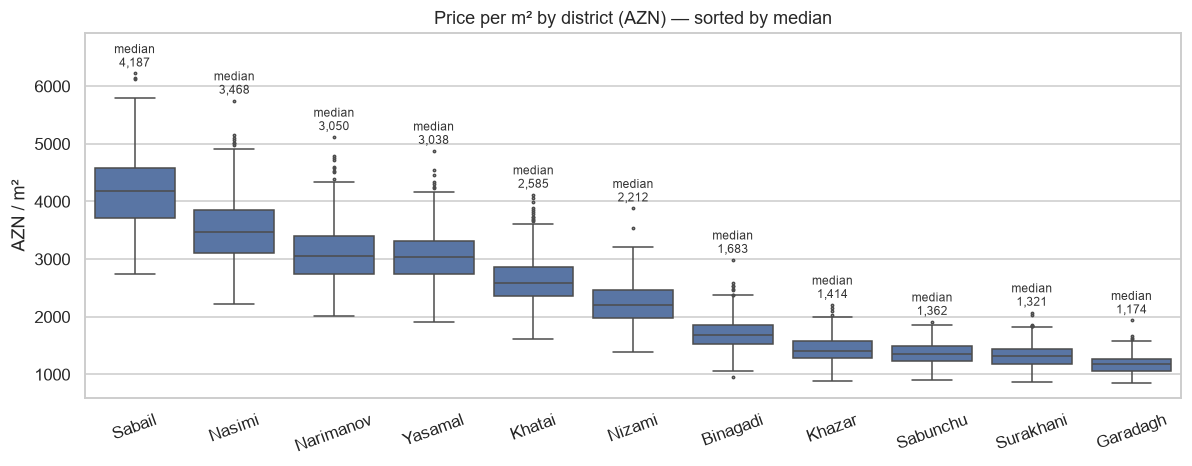

In [12]:
order = clean.groupby("district").price_per_m2.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.boxplot(data=clean, x="district", y="price_per_m2", order=order, color="#4C72B0", fliersize=1.5, ax=ax)
for i, d in enumerate(order):
    s = clean.loc[clean.district == d, "price_per_m2"]
    ax.text(i, s.max() + 120, f"median\n{s.median():,.0f}", ha="center", fontsize=8, color="#333")
ax.set_ylim(top=clean.price_per_m2.max() + 700)
ax.set_title("Price per m² by district (AZN) — sorted by median"); ax.set_xlabel(""); ax.set_ylabel("AZN / m²")
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig("images/district_price.png", bbox_inches="tight"); plt.show()

In [13]:
feat = ["new_building", "renovated", "title_deed", "metro_nearby", "first_floor", "top_floor"]
raw_gap = pd.DataFrame({f: [clean.loc[clean[f] == True, "price_per_m2"].median(),
                            clean.loc[clean[f] == False, "price_per_m2"].median()] for f in feat},
                       index=["with", "without"]).T
raw_gap["naive gap"] = (raw_gap["with"] / raw_gap["without"] - 1).map("{:+.1%}".format)
raw_gap.round(0)

,with,without,naive gap
new_building,2512.0,2539.0,-1.0%
renovated,2596.0,2428.0,+6.9%
title_deed,2571.0,2367.0,+8.6%
metro_nearby,3032.0,1666.0,+82.0%
first_floor,2381.0,2539.0,-6.2%
top_floor,2479.0,2527.0,-1.9%


Naive gaps are **confounded** — e.g. new buildings are more common in cheaper outer districts, and metro access is concentrated in the centre. A regression that controls for district and other features is needed.

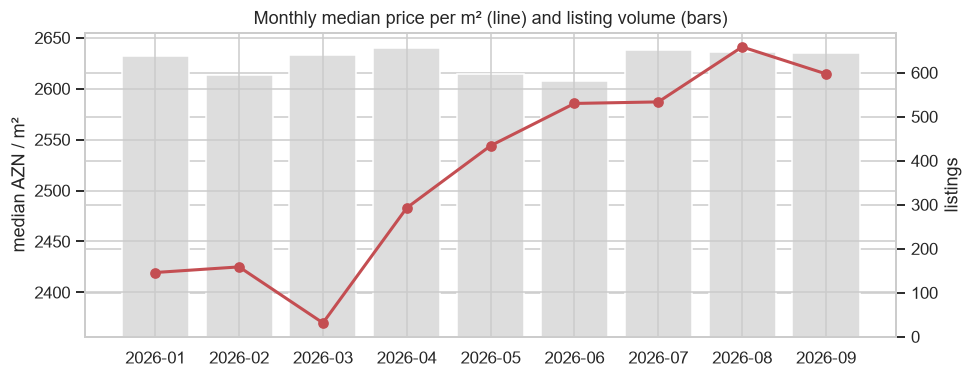

In [14]:
m = clean.groupby("listed_month").agg(median_ppm=("price_per_m2", "median"), listings=("listing_id", "count"))
fig, ax = plt.subplots(figsize=(9, 3.6)); ax2 = ax.twinx()
ax2.bar(m.index, m.listings, color="#DDDDDD", label="listings"); ax2.set_ylabel("listings")
ax.plot(m.index, m.median_ppm, marker="o", color="#C44E52", lw=2); ax.set_ylabel("median AZN / m²")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.set_title("Monthly median price per m² (line) and listing volume (bars)")
plt.tight_layout(); plt.savefig("images/monthly_trend.png", bbox_inches="tight"); plt.show()

## 6. Hedonic price model
$\log(\text{price per m}^2) = \beta_0 + \sum \beta_d\,\text{district}_d + \beta\cdot\text{features} + \gamma\log(\text{area}) + \delta\cdot\text{month} + \varepsilon$

Coefficients become % premiums via $e^{\beta}-1$. Reference district: **Khatai** (mid-priced). Rows with an unknown yes/no attribute (~4% per field) are excluded from the model only.

In [15]:
mdl = clean.dropna(subset=feat).copy()
mdl[feat] = mdl[feat].astype(int)
mdl["log_area"] = np.log(mdl.area)
mdl["month"] = mdl.listed_date.dt.month - 1
X = pd.concat([pd.get_dummies(mdl.district, prefix="d", dtype=int).drop(columns="d_Khatai"),
               mdl[feat + ["log_area", "month"]]], axis=1)
y = np.log(mdl.price_per_m2.values)
Xc = np.column_stack([np.ones(len(X)), X.values]).astype(float)
beta, *_ = np.linalg.lstsq(Xc, y, rcond=None)
resid = y - Xc @ beta
dof = len(y) - Xc.shape[1]; sigma2 = resid @ resid / dof
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xc.T @ Xc)))
t = stats.t.ppf(0.975, dof)
coef = pd.DataFrame({"beta": beta, "se": se}, index=["const"] + list(X.columns))
coef["premium"] = np.exp(coef.beta) - 1
coef["ci_low"], coef["ci_high"] = np.exp(coef.beta - t*coef.se) - 1, np.exp(coef.beta + t*coef.se) - 1
coef["p_value"] = 2 * stats.t.sf(np.abs(coef.beta / coef.se), dof)
r2 = 1 - resid.var() / y.var()
print(f"n = {len(y):,} | in-sample R² = {r2:.3f}")
coef.drop("const").assign(**{c: coef[c].map('{:+.1%}'.format) for c in ["premium","ci_low","ci_high"]}) \
    [["premium","ci_low","ci_high","p_value"]].round(4)

n = 4,782 | in-sample R² = 0.915


,premium,ci_low,ci_high,p_value
d_Binagadi,-33.7%,-34.7%,-32.8%,0.0
d_Garadagh,-53.4%,-54.3%,-52.4%,0.0
d_Khazar,-43.1%,-44.1%,-42.1%,0.0
d_Narimanov,+17.0%,+15.4%,+18.7%,0.0
d_Nasimi,+31.6%,+29.8%,+33.4%,0.0
d_Nizami,-14.2%,-15.5%,-12.9%,0.0
d_Sabail,+60.8%,+58.1%,+63.6%,0.0
d_Sabunchu,-46.0%,-46.9%,-45.0%,0.0
d_Surakhani,-48.1%,-49.0%,-47.2%,0.0
d_Yasamal,+14.5%,+12.9%,+16.0%,0.0


In [16]:
# out-of-sample check (5-fold CV) on total price
kf = KFold(5, shuffle=True, random_state=0)
pred_log = cross_val_predict(LinearRegression(), X, y, cv=kf)
pred_price = np.exp(pred_log) * mdl.area.values
ss_res = ((y - pred_log)**2).sum(); cv_r2 = 1 - ss_res / ((y - y.mean())**2).sum()
cv_mape = np.mean(np.abs(pred_price - mdl.price_azn.values) / mdl.price_azn.values)
print(f"5-fold CV R² (log price/m²) = {cv_r2:.3f} | CV MAPE on price = {cv_mape:.1%}")

5-fold CV R² (log price/m²) = 0.914 | CV MAPE on price = 9.7%


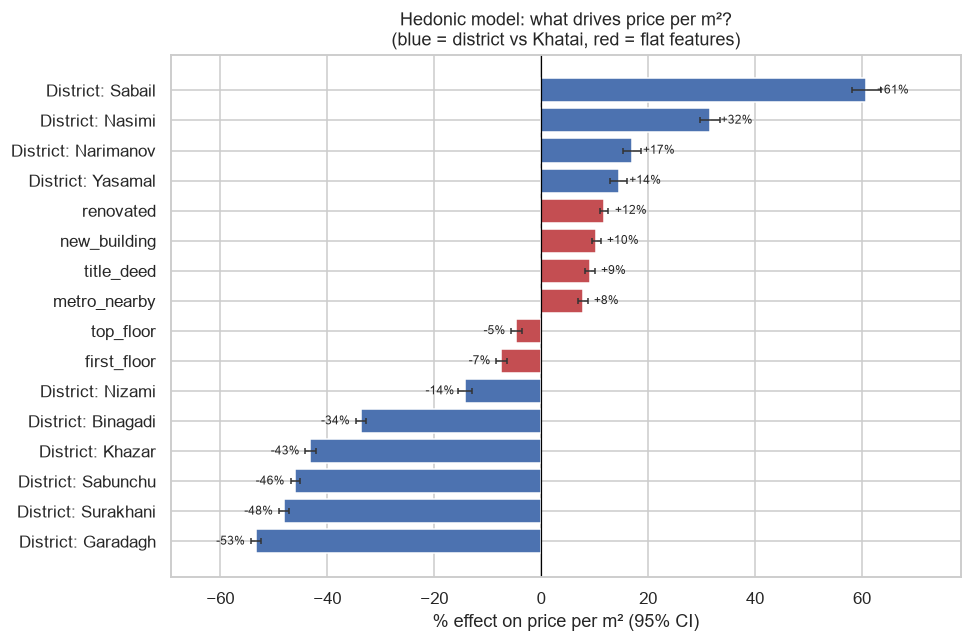

In [17]:
plot = coef.drop(["const", "month", "log_area"]).copy()
plot.index = [i.replace("d_", "District: ") for i in plot.index]
plot = plot.sort_values("premium")
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#4C72B0" if i.startswith("District") else "#C44E52" for i in plot.index]
ax.barh(plot.index, plot.premium * 100, color=colors, xerr=[(plot.premium - plot.ci_low) * 100, (plot.ci_high - plot.premium) * 100],
        error_kw=dict(ecolor="#333", lw=1, capsize=2))
for i, v in enumerate(plot.premium * 100):
    ax.text(v + (2 if v >= 0 else -2), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% effect on price per m² (95% CI)"); ax.set_title("Hedonic model: what drives price per m²?\n(blue = district vs Khatai, red = flat features)")
ax.set_xlim(plot.ci_low.min()*100 - 15, plot.ci_high.max()*100 + 15)
plt.tight_layout(); plt.savefig("images/feature_premiums.png", bbox_inches="tight"); plt.show()

## 7. Mispricing flags for moderators
Listings priced **>25% below** the model's fair value are either bargains or bait/fraud and should be reviewed; **>25% above** are likely to sit unsold.

,listings,share
flag,,
fair,4586,95.9%
over-priced,154,3.2%
under-priced (review),42,0.9%


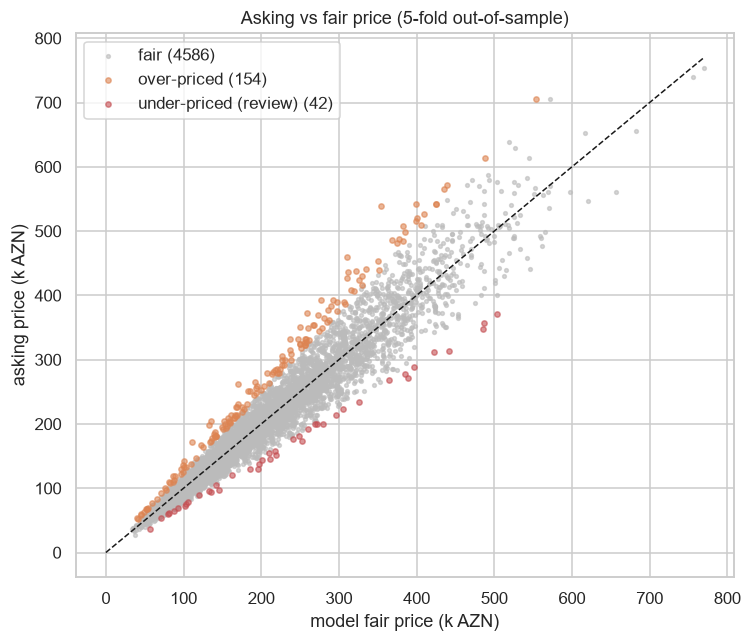

,listing_id,district,rooms,area,price_azn,fair_price,gap
374,L104147,Binagadi,1,29.3,37100.0,56200.0,-34%
5282,L101653,Nasimi,1,52.2,130600.0,196400.0,-34%
2777,L100222,Binagadi,3,100.7,96500.0,145000.0,-33%
4522,L102234,Binagadi,4,115.7,145500.0,211900.0,-31%
1582,L105985,Narimanov,2,71.9,173800.0,253000.0,-31%
5118,L104931,Nizami,3,98.5,151900.0,219300.0,-31%
145,L101491,Surakhani,5,154.3,137000.0,197700.0,-31%
2820,L104574,Surakhani,3,91.7,94400.0,135100.0,-30%


In [18]:
mdl["fair_price"] = (np.exp(pred_log) * mdl.area).round(-2)
mdl["gap"] = mdl.price_azn / mdl.fair_price - 1
mdl["flag"] = np.select([mdl.gap < -0.25, mdl.gap > 0.25], ["under-priced (review)", "over-priced"], "fair")
display(mdl.flag.value_counts().to_frame("listings").assign(share=lambda d: (d.listings/len(mdl)).map("{:.1%}".format)))
fig, ax = plt.subplots(figsize=(7, 6))
pal = {"fair": "#BBBBBB", "under-priced (review)": "#C44E52", "over-priced": "#DD8452"}
for f, g in mdl.groupby("flag"):
    ax.scatter(g.fair_price/1000, g.price_azn/1000, s=6 if f == "fair" else 12, alpha=.6, color=pal[f], label=f"{f} ({len(g)})")
lim = [0, mdl[["fair_price","price_azn"]].max().max()/1000]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("model fair price (k AZN)"); ax.set_ylabel("asking price (k AZN)"); ax.legend()
ax.set_title("Asking vs fair price (5-fold out-of-sample)")
plt.tight_layout(); plt.savefig("images/mispricing.png", bbox_inches="tight"); plt.show()
mdl.sort_values("gap")[["listing_id","district","rooms","area","price_azn","fair_price","gap"]].head(8).assign(gap=lambda d: d.gap.map("{:+.0%}".format))

## 8. Findings & recommendations

In [19]:
p = coef.premium
top = plot[plot.index.str.startswith("District")].premium
rec = pd.DataFrame([
 ["Feed quality", f"Only {len(clean)/len(raw):.1%} of raw rows usable; {dup_stats['exact_duplicates']+dup_stats['reposts']} duplicates/reposts, {len(quarantine)} rows failed validation",
  "Validate at upload: numeric price + currency dropdown, district picklist, area in m² only; block reposts of the same flat"],
 ["Currency", f"{clean.price_was_usd.mean():.1%} of prices were quoted in USD",
  "Store price + currency separately; show both on the card"],
 ["Location", f"District range: {top.idxmin().split(': ')[1]} {top.min():+.0%} to {top.idxmax().split(': ')[1]} {top.max():+.0%} vs Khatai",
  "Use district as the first filter and in price-alert defaults"],
 ["Legal status", f"Title deed (çıxarış) adds {p['title_deed']:+.1%} per m²",
  "Make 'title deed' a mandatory, verified badge — it is a price driver buyers pay for"],
 ["Condition", f"Renovation {p['renovated']:+.1%}, new building {p['new_building']:+.1%}, metro {p['metro_nearby']:+.1%}",
  "Surface these as structured filters, not free text"],
 ["Floor", f"Ground floor {p['first_floor']:+.1%}, top floor {p['top_floor']:+.1%}",
  "Show floor as 'X / Y' with ground/top badges"],
 ["Market trend", f"Prices drift {np.exp(coef.beta['month'])-1:+.2%} per month, controlling for mix",
  "Refresh fair-price model monthly"],
 ["Moderation", f"{(mdl.flag=='under-priced (review)').sum()} listings priced >25% below fair value (CV MAPE {cv_mape:.1%})",
  "Auto-queue under-priced listings for fraud/bait review before publishing"],
], columns=["Area", "Evidence", "Recommendation"])
pd.set_option("display.max_colwidth", None)
rec

,Area,Evidence,Recommendation
0,Feed quality,"Only 88.9% of raw rows usable; 349 duplicates/reposts, 360 rows failed validation","Validate at upload: numeric price + currency dropdown, district picklist, area in m² only; block reposts of the same flat"
1,Currency,17.7% of prices were quoted in USD,Store price + currency separately; show both on the card
2,Location,District range: Garadagh -53% to Sabail +61% vs Khatai,Use district as the first filter and in price-alert defaults
3,Legal status,Title deed (çıxarış) adds +9.2% per m²,"Make 'title deed' a mandatory, verified badge — it is a price driver buyers pay for"
4,Condition,"Renovation +11.8%, new building +10.3%, metro +7.9%","Surface these as structured filters, not free text"
5,Floor,"Ground floor -7.4%, top floor -4.7%",Show floor as 'X / Y' with ground/top badges
6,Market trend,"Prices drift +0.82% per month, controlling for mix",Refresh fair-price model monthly
7,Moderation,42 listings priced >25% below fair value (CV MAPE 9.7%),Auto-queue under-priced listings for fraud/bait review before publishing
